# Taller Análisis Exploratorio de Datos

Dataset: **Telco Customer Churn** (IBM)

## Paso 1: Carga de datos

Abra el archivo en Excel o bloc de notas, y revise sí hay algo particular con los datos. Este paso es importante para evitar problemas posteriores al cargar los datos.

Cargar el archivo dado, que contiene un dataset cuya información puede consultar en [IBM](https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113).

Responda las siguientes preguntas:

- ¿Cuántas filas y columnas tiene el dataframe?
- ¿De qué tipo de dato es cada columna?
- ¿Las variables están en el tipo de dato correcto para su contenido?

Al abrir el archivo en el bloc de notas se observa algo particular: la columna **Total Charges**
tiene algunos registros con un **espacio en blanco** en lugar de un número. Pandas no reconoce ese
espacio como dato nulo, así que se carga primero sin avisarle, para ver el problema.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data_path = 'Telco_customer_churn.csv'

df = pd.read_csv(data_path)

df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

Se observa que la variable **Total Charges** quedó con el tipo de dato incorrecto (`object` en lugar
de `float64`), porque tiene datos nulos que no fueron identificados por Pandas.

Hay dos maneras de solucionarlo. La primera es convertir la columna después de cargarla:

In [3]:
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

La segunda, y la que se va a usar de aquí en adelante, es indicarle a Pandas desde la carga cuáles
valores debe tratar como nulos:

In [4]:
df = pd.read_csv(
    data_path,
    na_values=[' ']
    )

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [5]:
# Número de filas y columnas
print('Número de filas   : ', df.shape[0])
print('Número de columnas: ', df.shape[1])

Número de filas   :  7043
Número de columnas:  33


<div style="background:#fafafa; border:1px solid #d8d8d8; border-left:4px solid #555;border-radius:4px; padding:14px 18px; margin:6px 0; font-size:14.5px; color:#222; line-height:1.55;">
<div style="font-weight:700; font-size:13.5px; color:#555; text-transform:uppercase; letter-spacing:.4px; margin-bottom:10px;">Respuestas — Paso 1</div>
<p style="margin:14px 0 3px 0;"><b>¿Cuántas filas y columnas tiene?</b></p>
<p>El dataframe tiene 7043 filas y 33 columnas.</p>
<p style="margin:14px 0 3px 0;"><b>¿Qué tipo de dato tiene cada columna?</b></p>
<p>Hay 4 columnas <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">float64</code>, 6 <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">int64</code> y 23 <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">object</code> (texto).</p>
<p style="margin:14px 0 3px 0;"><b>¿Están en el tipo correcto?</b></p>
<p>No todas. <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Total Charges</code> venía como <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">object</code> porque 11 registros tenían un espacio en blanco en vez de un número (se corrige cargando con <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">na_values=[' ']</code>). Además <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Value</code> y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Count</code> son numéricas pero en realidad son categóricas, y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Zip Code</code> es <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">int64</code> pero es un código, no una magnitud.</p>
</div>

## Paso 2: Exploración inicial de los datos

Responda las siguientes preguntas:

- ¿Hay valores fuera de rango o imposibles, según el dominio del problema?
- ¿Hay variables que no varían?
- Qué variables *cualitativas* tienen muchos valores únicos (alta cardinalidad)?
- ¿Hay claves primarias o identificadores únicos?

In [6]:
# Estadísticas descriptivas de las variables numéricas
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,2283.300441,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,2266.771362,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,18.800000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,401.450000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,1397.475000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,3794.737500,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,8684.800000,1.000000,100.000000,6500.000000


In [7]:
# Estadísticas descriptivas de las variables cualitativas
df.describe(include='object').T

,count,unique,top,freq
CustomerID,7043,7043,3668-QPYBK,1
Country,7043,1,United States,7043
State,7043,1,California,7043
City,7043,1129,Los Angeles,305
Lat Long,7043,1652,"33.964131, -118.272783",5
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361


In [8]:
# La variable Count toma un solo valor
print('Valores de la variable Count   : ', df['Count'].unique())
print('Valores de la variable Country : ', df['Country'].unique())
print('Valores de la variable State   : ', df['State'].unique())

Valores de la variable Count   :  [1]
Valores de la variable Country :  ['United States']
Valores de la variable State   :  ['California']


In [9]:
# Etiquetas de las variables cualitativas, para buscar categorías extrañas o mal escritas
cat_cols = df.drop(['CustomerID', 'Country', 'State', 'City', 'Lat Long'], axis=1).select_dtypes(include=['object']).columns

for col in cat_cols:
    print('Etiquetas de la variable ', col, ':\n')
    print(df[col].unique())
    print('\n')

Etiquetas de la variable  Gender :

['Male' 'Female']


Etiquetas de la variable  Senior Citizen :

['No' 'Yes']


Etiquetas de la variable  Partner :

['No' 'Yes']


Etiquetas de la variable  Dependents :

['No' 'Yes']


Etiquetas de la variable  Phone Service :

['Yes' 'No']


Etiquetas de la variable  Multiple Lines :

['No' 'Yes' 'No phone service']


Etiquetas de la variable  Internet Service :

['DSL' 'Fiber optic' 'No']


Etiquetas de la variable  Online Security :

['Yes' 'No' 'No internet service']


Etiquetas de la variable  Online Backup :

['Yes' 'No' 'No internet service']


Etiquetas de la variable  Device Protection :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Tech Support :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Streaming TV :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Streaming Movies :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Contract :

['Month-to-month' 'Two year' 'One year']



In [10]:
# Cardinalidad de las variables cualitativas: número de valores diferentes
cardinalidad = df.select_dtypes(include=['object']).describe().T['unique']
cardinalidad.sort_values(ascending=False)

CustomerID           7043
Lat Long             1652
City                 1129
Churn Reason           20
Payment Method          4
Online Backup           3
Online Security         3
Contract                3
Streaming Movies        3
Streaming TV            3
Tech Support            3
Device Protection       3
Internet Service        3
Multiple Lines          3
Gender                  2
Phone Service           2
Dependents              2
Partner                 2
Paperless Billing       2
Senior Citizen          2
Churn Label             2
Country                 1
State                   1
Name: unique, dtype: object

In [11]:
# Verificación de claves primarias: una clave primaria toma tantos valores
# diferentes como registros hay en el dataframe
print('Número de registros            : ', df.shape[0])
print('Valores únicos de CustomerID   : ', df['CustomerID'].describe()['unique'])
print('Valores únicos de Zip Code     : ', len(df['Zip Code'].unique()))
print('Valores únicos de Lat Long     : ', df['Lat Long'].describe()['unique'])

Número de registros            :  7043
Valores únicos de CustomerID   :  7043
Valores únicos de Zip Code     :  1652
Valores únicos de Lat Long     :  1652


<div style="background:#fafafa; border:1px solid #d8d8d8; border-left:4px solid #555;border-radius:4px; padding:14px 18px; margin:6px 0; font-size:14.5px; color:#222; line-height:1.55;">
<div style="font-weight:700; font-size:13.5px; color:#555; text-transform:uppercase; letter-spacing:.4px; margin-bottom:10px;">Respuestas — Paso 2</div>
<p style="margin:14px 0 3px 0;"><b>¿Hay valores fuera de rango o imposibles?</b></p>
<p>No. Con <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">describe()</code> se ve que todas las variables numéricas caen en rangos lógicos (<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tenure Months</code> entre 0 y 72 meses, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Monthly Charges</code> entre 18 y 119 dólares, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Score</code> entre 5 y 100, etc.). Lo único llamativo es <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tenure Months = 0</code> en algunos clientes, pero son clientes recién ingresados, no un error.</p>
<p style="margin:14px 0 3px 0;"><b>¿Hay variables que no varían?</b></p>
<p><code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Count</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Country</code> y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">State</code> toman un solo valor en todo el dataframe.</p>
<p style="margin:14px 0 3px 0;"><b>¿Qué variables tienen alta cardinalidad?</b></p>
<p><code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">CustomerID</code> (7043), <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Lat Long</code> (1652), <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">City</code> (1129) y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Zip Code</code> (1652, aunque numérica). <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code> tiene 20 categorías, cardinalidad media.</p>
<p style="margin:14px 0 3px 0;"><b>¿Hay clave primaria?</b></p>
<p><code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">CustomerID</code>: tiene tantos valores únicos como filas y no tiene nulos.</p>
</div>

## Paso 3: Identificación de datos duplicados, datos nulos y problemas de formateo

Descarte las variables que solo toman un valor y las que son clave primaria. También descarte las variables **City** y **Lat Long**.

Responda las siguientes preguntas:

- ¿Qué variables tienen valores nulos? ¿En qué proporción?
- ¿Hay registros duplicados?
- ¿Hay variables con problemas de formateo (fechas, monedas, mayúsculas/minúsculas)?

### Descarte de variables

Según lo encontrado en el Paso 2 se descartan:

- `Count`, `Country` y `State`, porque toman un solo valor.
- `CustomerID`, porque es la clave primaria. En lugar de eliminarla se convierte en índice, para no
  perder la identificación de cada cliente.
- `City` y `Lat Long`, tal como lo pide el enunciado.

In [12]:
df = df.set_index('CustomerID')
df = df.drop(columns=['Count', 'Country', 'State', 'City', 'Lat Long'])

df.head()

,Zip Code,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
CustomerID,,,,,,,,,,,,,,,,,,,,,
3668-QPYBK,90003,33.964131,-118.272783,Male,No,No,No,2,Yes,No,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
9237-HQITU,90005,34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
9305-CDSKC,90006,34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
7892-POOKP,90010,34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
0280-XJGEX,90015,34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


In [13]:
print('Número de filas   : ', df.shape[0])
print('Número de columnas: ', df.shape[1])

Número de filas   :  7043
Número de columnas:  27


### Datos nulos

In [14]:
# Variables con datos nulos
df.isnull().sum().sort_values(ascending=False).head()

Churn Reason     5174
Total Charges      11
Tech Support        0
CLTV                0
Churn Score         0
dtype: int64

In [15]:
# Proporción de datos nulos
nulos = df.isnull().sum()/df.shape[0]*100
nulos.sort_values(ascending=False).head()

Churn Reason     73.463013
Total Charges     0.156183
Tech Support      0.000000
CLTV              0.000000
Churn Score       0.000000
dtype: float64

In [16]:
# ¿Por qué faltan estos datos? Se revisan los registros con Total Charges nulo
df[df['Total Charges'].isnull()][['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Label']]

,Tenure Months,Monthly Charges,Total Charges,Churn Label
CustomerID,,,,
4472-LVYGI,0,52.55,NaN,No
3115-CZMZD,0,20.25,NaN,No
5709-LVOEQ,0,80.85,NaN,No
4367-NUYAO,0,25.75,NaN,No
1371-DWPAZ,0,56.05,NaN,No
7644-OMVMY,0,19.85,NaN,No
3213-VVOLG,0,25.35,NaN,No
2520-SGTTA,0,20.00,NaN,No
2923-ARZLG,0,19.70,NaN,No


In [17]:
# ¿Y los de Churn Reason? Se comparan con la variable Churn Label
print('Clientes con Churn Reason nulo:')
print(df[df['Churn Reason'].isnull()]['Churn Label'].value_counts())
print('\nClientes con Churn Reason NO nulo:')
print(df[df['Churn Reason'].notnull()]['Churn Label'].value_counts())

Clientes con Churn Reason nulo:


Churn Label
No    5174
Name: count, dtype: int64

Clientes con Churn Reason NO nulo:
Churn Label
Yes    1869
Name: count, dtype: int64


Los dos casos de datos nulos tienen una explicación clara:

- Los **11 registros sin `Total Charges`** son exactamente los clientes con **`Tenure Months` = 0**,
  es decir, clientes nuevos que todavía no han facturado ningún mes. Por eso el valor correcto para
  imputarles es **0**, y no el promedio de la variable.
- Los **5174 registros sin `Churn Reason`** son exactamente los clientes con **`Churn Label` = No**.
  Un cliente que no se ha ido no tiene razón de cancelación. No se debe imputar, porque se estaría
  inventando información.

Se imputa `Total Charges` con `fillna(0)`: 

In [18]:
df['Total Charges'] = df['Total Charges'].fillna(0)

print('Datos nulos en Total Charges: ', df['Total Charges'].isnull().sum())

Datos nulos en Total Charges:  0


### Registros duplicados

In [19]:
print('Número de registros duplicados: ', df.duplicated().sum())

Número de registros duplicados:  0


In [20]:
# También se revisa si hay clientes repetidos por identificador
print('Identificadores repetidos: ', df.index.duplicated().sum())

Identificadores repetidos:  0


### Problemas de formateo

In [21]:
# Monedas: se revisa que las variables de dinero sean numéricas y sin símbolos
df[['Monthly Charges', 'Total Charges', 'CLTV']].describe()

,Monthly Charges,Total Charges,CLTV
count,7043.000000,7043.000000,7043.000000
mean,64.761692,2279.734304,4400.295755
std,30.090047,2266.794470,1183.057152
min,18.250000,0.000000,2003.000000
25%,35.500000,398.550000,3469.000000
50%,70.350000,1394.550000,4527.000000
75%,89.850000,3786.600000,5380.500000
max,118.750000,8684.800000,6500.000000


In [22]:
# Mayúsculas y minúsculas: se revisan de nuevo las etiquetas de las cualitativas
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    print('Etiquetas de la variable ', col, ':\n')
    print(df[col].unique())
    print('\n')

Etiquetas de la variable  Gender :

['Male' 'Female']


Etiquetas de la variable  Senior Citizen :

['No' 'Yes']


Etiquetas de la variable  Partner :

['No' 'Yes']


Etiquetas de la variable  Dependents :

['No' 'Yes']


Etiquetas de la variable  Phone Service :

['Yes' 'No']


Etiquetas de la variable  Multiple Lines :

['No' 'Yes' 'No phone service']


Etiquetas de la variable  Internet Service :

['DSL' 'Fiber optic' 'No']


Etiquetas de la variable  Online Security :

['Yes' 'No' 'No internet service']


Etiquetas de la variable  Online Backup :

['Yes' 'No' 'No internet service']


Etiquetas de la variable  Device Protection :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Tech Support :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Streaming TV :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Streaming Movies :

['No' 'Yes' 'No internet service']


Etiquetas de la variable  Contract :

['Month-to-month' 'Two year' 'One year']



In [23]:
# Se comprueba que Churn Label y Churn Value tienen la misma información
print(df[df['Churn Label'] == 'Yes']['Churn Value'].value_counts())
print(df[df['Churn Label'] == 'No']['Churn Value'].value_counts())

Churn Value
1    1869
Name: count, dtype: int64
Churn Value
0    5174
Name: count, dtype: int64


In [24]:
# Se comprueba que 'No internet service' aparece solo cuando Internet Service es 'No'
print(df[df['Internet Service'] == 'No']['Online Security'].value_counts())
print('\n')
print(df[df['Online Security'] == 'No internet service']['Internet Service'].value_counts())

Online Security
No internet service    1526
Name: count, dtype: int64


Internet Service
No    1526
Name: count, dtype: int64


<div style="background:#fafafa; border:1px solid #d8d8d8; border-left:4px solid #555;border-radius:4px; padding:14px 18px; margin:6px 0; font-size:14.5px; color:#222; line-height:1.55;">
<div style="font-weight:700; font-size:13.5px; color:#555; text-transform:uppercase; letter-spacing:.4px; margin-bottom:10px;">Respuestas — Paso 3</div>
<p style="margin:14px 0 3px 0;"><b>¿Qué variables tienen nulos y en qué proporción?</b></p>
<p><code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code> (5174 nulos, 73.46%) y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Total Charges</code> (11 nulos, 0.16%). Los de <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Total Charges</code> son clientes con <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tenure Months = 0</code> (aún no facturan), se imputan con 0. Los de <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code> son clientes que no se fueron (<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Label = No</code>), no se imputan porque no tiene sentido inventarles una razón de cancelación.</p>
<p style="margin:14px 0 3px 0;"><b>¿Hay duplicados?</b></p>
<p>No. Ni filas completas ni <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">CustomerID</code> repetidos.</p>
<p style="margin:14px 0 3px 0;"><b>¿Hay problemas de formateo?</b></p>
<p>El único fue <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Total Charges</code> (texto por los espacios en blanco), ya corregido. No hay problemas de mayúsculas/minúsculas ni fechas mal escritas. Sí hay redundancia: <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Label</code> y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Value</code> son la misma información, y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">'No internet service'</code> se repite en 6 columnas siempre que <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Internet Service = No</code>.</p>
</div>

## Paso 4: Análisis de variables cuantitativas

Haga análisis de normalidad de las variables cuantitativas. Indique cuáles variables cumplen con el supuesto de normalidad y cuáles no.

Haga un análisis gráfico de outliers, y como resultado de este indique que variables tienen datos atípicos.

### Análisis de normalidad

Las variables cuantitativas del dataframe son `Tenure Months`, `Monthly Charges`, `Total Charges`,
`Churn Score` y `CLTV`.

No se analizan `Zip Code`, `Latitude` ni `Longitude` porque, aunque son numéricas, en realidad son
variables geográficas nominales. Tampoco `Churn Value`, porque es cualitativa (solo toma 0 y 1).

Para analizar la normalidad se usan histogramas y gráficos de densidad.

In [25]:
# Variables cuantitativas
cuanti = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Churn Score', 'CLTV']

df[cuanti].describe()

,Tenure Months,Monthly Charges,Total Charges,Churn Score,CLTV
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,58.699418,4400.295755
std,24.559481,30.090047,2266.794470,21.525131,1183.057152
min,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,9.000000,35.500000,398.550000,40.000000,3469.000000
50%,29.000000,70.350000,1394.550000,61.000000,4527.000000
75%,55.000000,89.850000,3786.600000,75.000000,5380.500000
max,72.000000,118.750000,8684.800000,100.000000,6500.000000


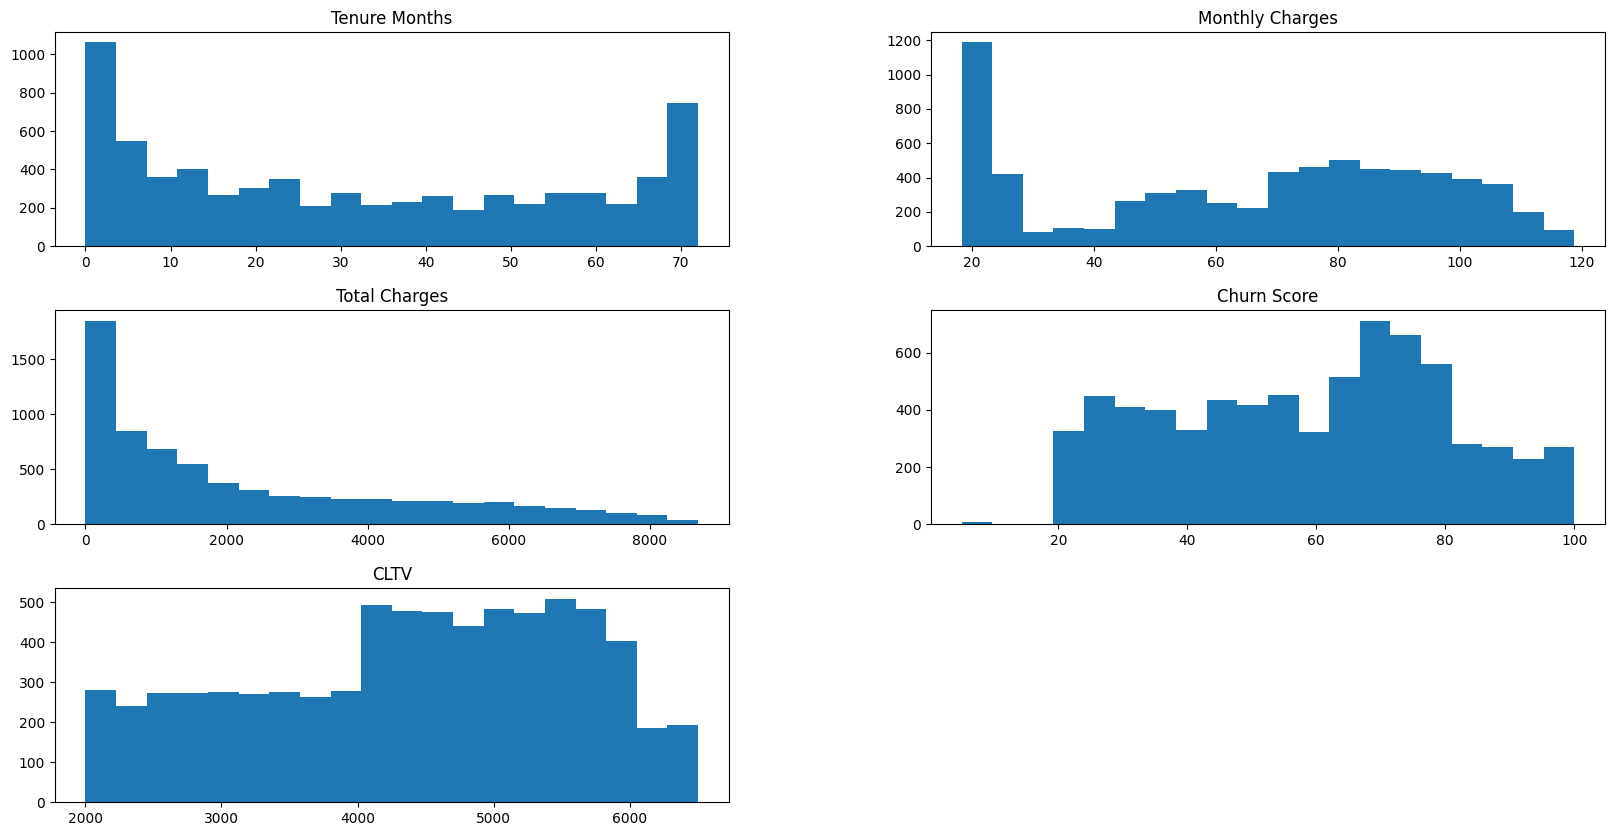

In [26]:
# Histogramas
df[cuanti].hist(
    figsize=(20, 10),
    bins=20,
    grid=False
    )
plt.show()

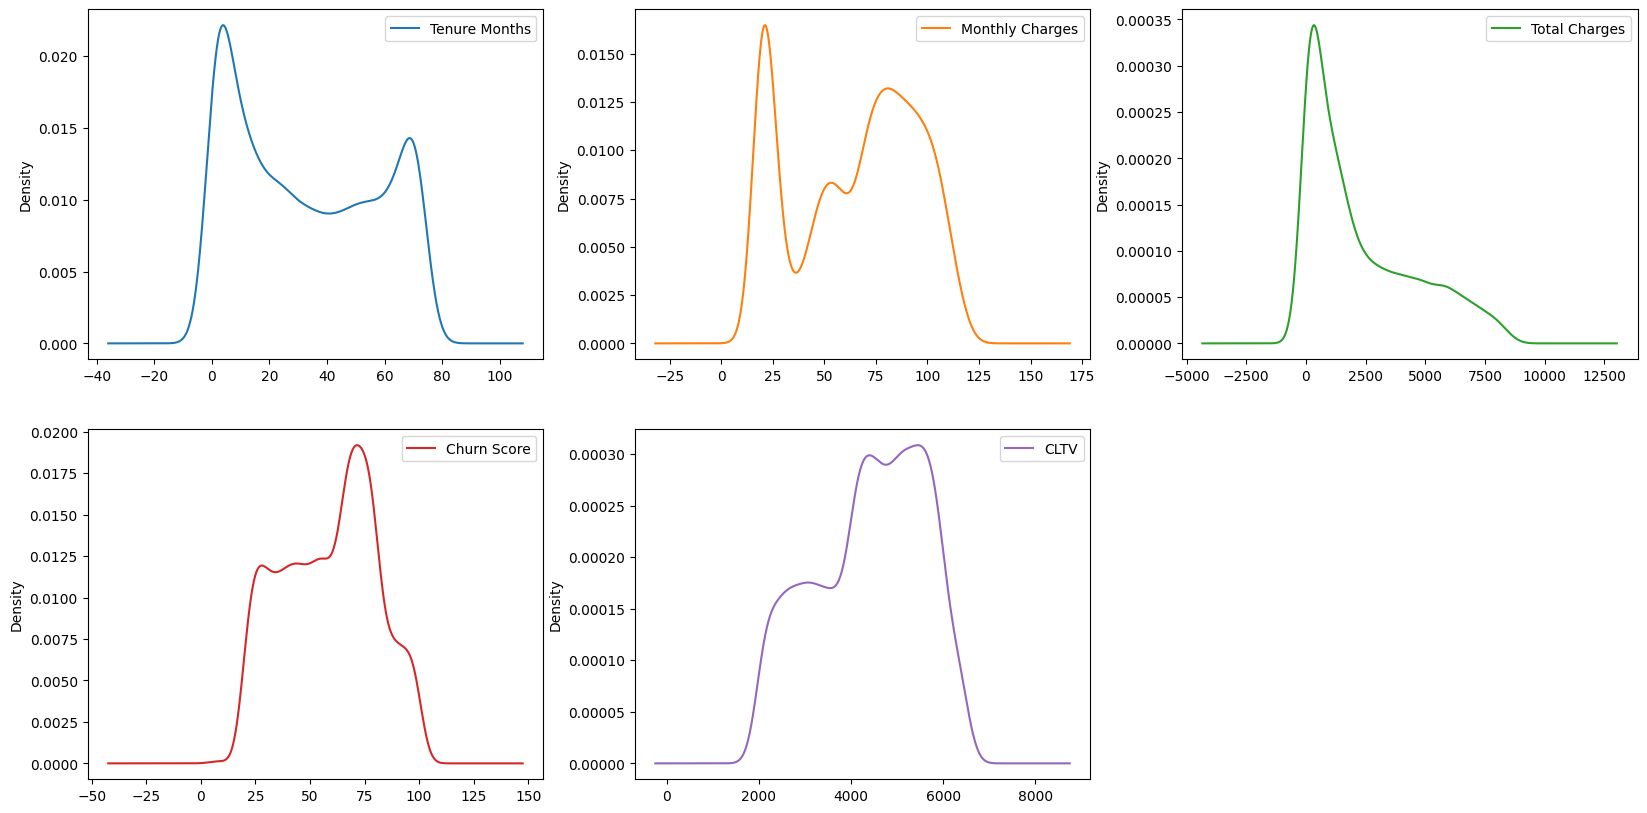

In [27]:
# Gráficos de densidad
df[cuanti].plot(
    kind='kde',
    figsize=(20, 10),
    subplots=True,
    layout=(2, 3),
    sharex=False,
    sharey=False
    )
plt.show()

In [28]:
# Como apoyo se calculan la curtosis y la asimetría de cada variable
for col in cuanti:
    print('Variable ', col, ':')
    print('   Curtosis (kurt): ', round(df[col].kurt(), 4))
    print('   Asimetría (skew):', round(df[col].skew(), 4))
    print('\n')

Variable  Tenure Months :
   Curtosis (kurt):  -1.3874
   Asimetría (skew): 0.2395


Variable  Monthly Charges :
   Curtosis (kurt):  -1.2573
   Asimetría (skew): -0.2205


Variable  Total Charges :
   Curtosis (kurt):  -0.2286
   Asimetría (skew): 0.9632


Variable  Churn Score :
   Curtosis (kurt):  -1.0057
   Asimetría (skew): -0.0898


Variable  CLTV :
   Curtosis (kurt):  -0.934
   Asimetría (skew): -0.3116




### Análisis gráfico de outliers

Para detectar datos atípicos se usan gráficos de cajas y bigotes. Si se observan puntos por fuera de
los bigotes, son valores atípicos.

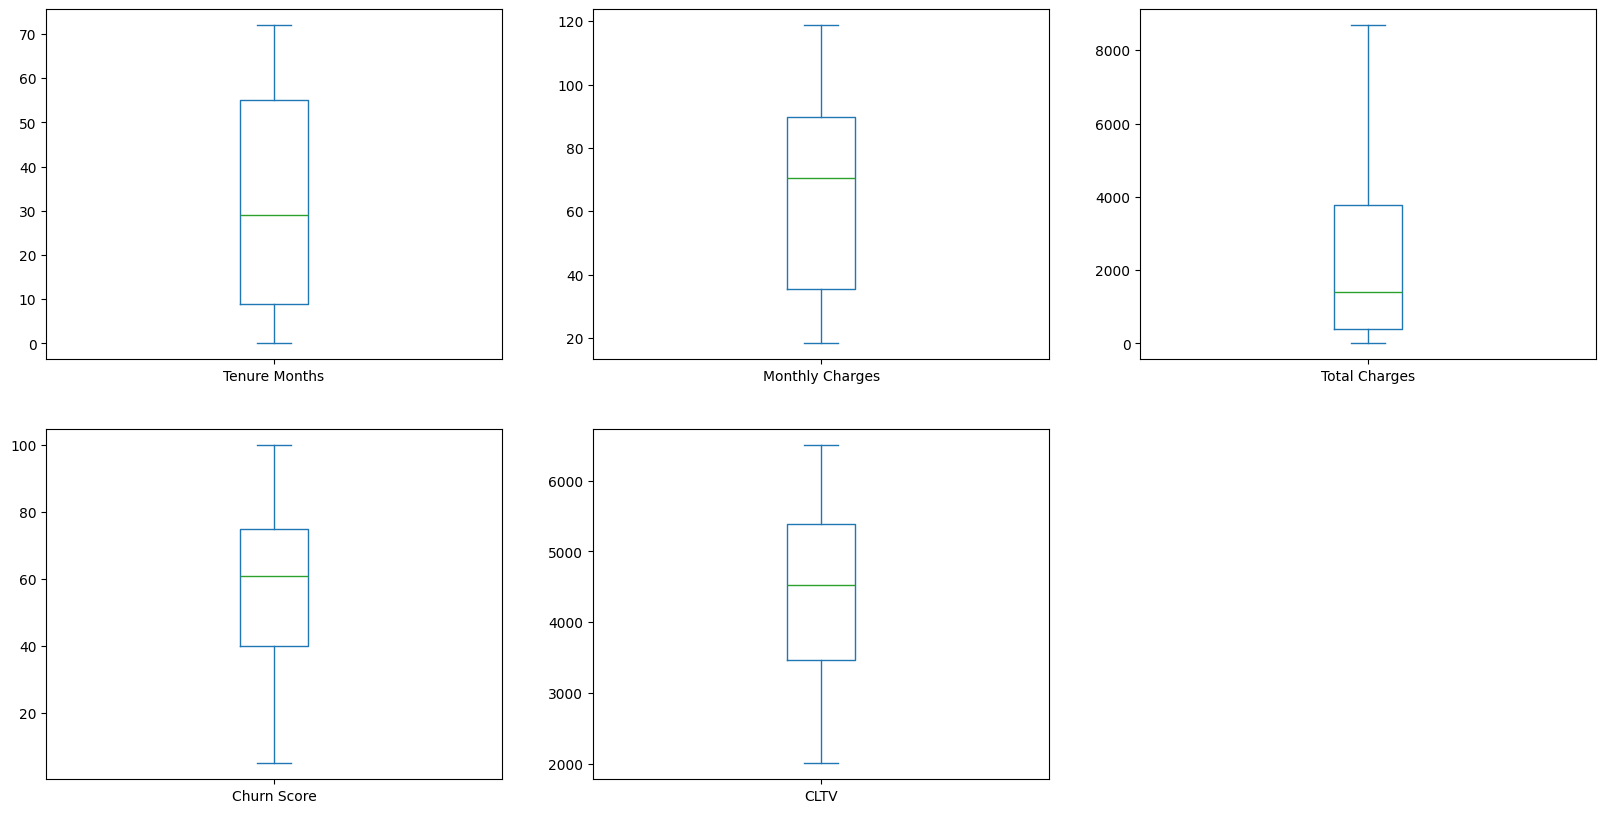

In [29]:
# Diagramas de caja y bigotes
df[cuanti].plot(
    kind='box',
    figsize=(20, 10),
    subplots=True,
    layout=(2, 3),
    sharex=False,
    sharey=False
    )
plt.show()

In [30]:
# Se comprueba numéricamente que ningún dato queda por fuera de los bigotes.
# Los bigotes van de Q1 - 1.5*IQR hasta Q3 + 1.5*IQR
for col in cuanti:
    q1 = df[col].describe()['25%']
    q3 = df[col].describe()['75%']
    iqr = q3 - q1
    inf = q1 - 1.5*iqr
    sup = q3 + 1.5*iqr
    atipicos = df[(df[col] < inf) | (df[col] > sup)].shape[0]
    print('Variable ', col, ':')
    print('   Bigote inferior: ', round(inf, 2), '   Mínimo real: ', df[col].min())
    print('   Bigote superior: ', round(sup, 2), '   Máximo real: ', df[col].max())
    print('   Datos atípicos : ', atipicos)
    print('\n')

Variable  Tenure Months :
   Bigote inferior:  -60.0    Mínimo real:  0
   Bigote superior:  124.0    Máximo real:  72
   Datos atípicos :  0


Variable  Monthly Charges :
   Bigote inferior:  -46.02    Mínimo real:  18.25
   Bigote superior:  171.38    Máximo real:  118.75
   Datos atípicos :  0


Variable  Total Charges :
   Bigote inferior:  -4683.52    Mínimo real:  0.0
   Bigote superior:  8868.67    Máximo real:  8684.8
   Datos atípicos :  0


Variable  Churn Score :
   Bigote inferior:  -12.5    Mínimo real:  5
   Bigote superior:  127.5    Máximo real:  100
   Datos atípicos :  0


Variable  CLTV :
   Bigote inferior:  601.75    Mínimo real:  2003
   Bigote superior:  8247.75    Máximo real:  6500
   Datos atípicos :  0




<div style="background:#fafafa; border:1px solid #d8d8d8; border-left:4px solid #555;border-radius:4px; padding:14px 18px; margin:6px 0; font-size:14.5px; color:#222; line-height:1.55;">
<div style="font-weight:700; font-size:13.5px; color:#555; text-transform:uppercase; letter-spacing:.4px; margin-bottom:10px;">Respuestas — Paso 4</div>
<p style="margin:14px 0 3px 0;"><b>Normalidad</b></p>
<p>Ninguna de las 5 variables cuantitativas es normal. <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tenure Months</code> y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Monthly Charges</code> son bimodales (dos picos), <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Total Charges</code> está sesgada a la derecha, y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Score</code>/<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">CLTV</code> son muy planas. La curtosis es negativa en todos los casos.</p>
<p style="margin:14px 0 3px 0;"><b>Outliers</b></p>
<p>Ninguna variable tiene datos atípicos: en los boxplots no hay puntos fuera de los bigotes. Todas están acotadas por el negocio (ej. <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tenure Months</code> no pasa de 72 meses), así que el rango es amplio y no hay atípicos.</p>
</div>

## Paso 5: Análisis de variables cualitativas

Responda a las siguientes preguntas:

- ¿Cómo se comportan las variables cualitativas?
- ¿Existen variables de alta cardinalidad?
- ¿Existen categorías atípicas?

In [31]:
# Se seleccionan las variables cualitativas. Se añade Churn Value porque también es cualitativa,
# y se quita Churn Label porque tiene la misma información que Churn Value
cat_vars = list(df.select_dtypes(include=['object']).columns) + ['Churn Value']
cat_vars = [var for var in cat_vars if var not in ['Churn Label']]

print('Número de variables cualitativas: ', len(cat_vars))
print(cat_vars)

Número de variables cualitativas:  18
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Churn Reason', 'Churn Value']


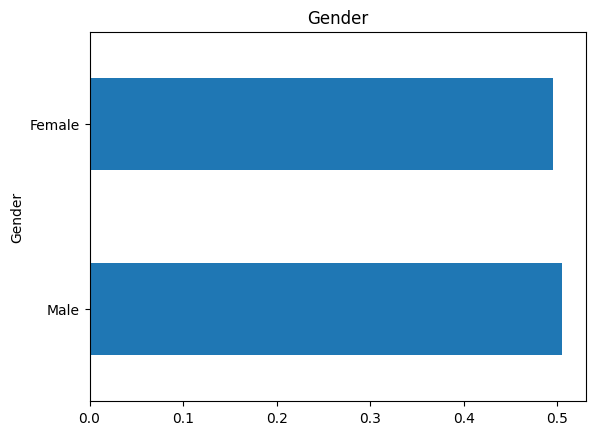

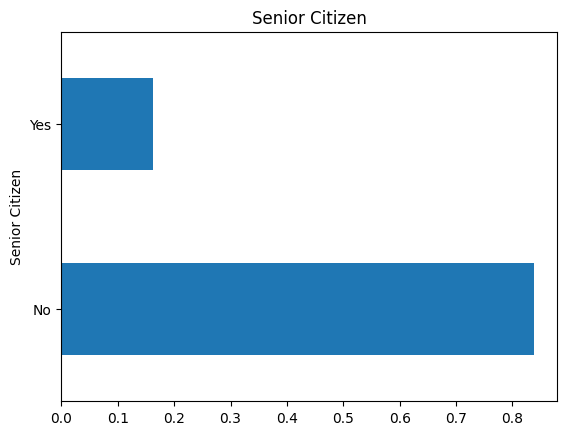

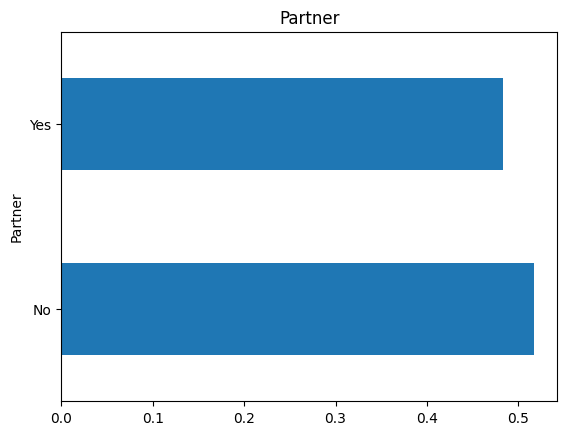

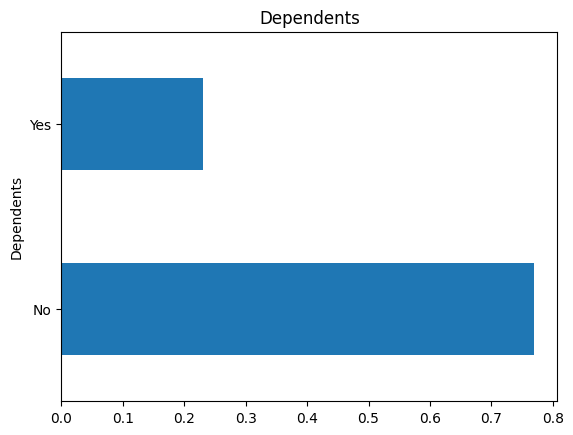

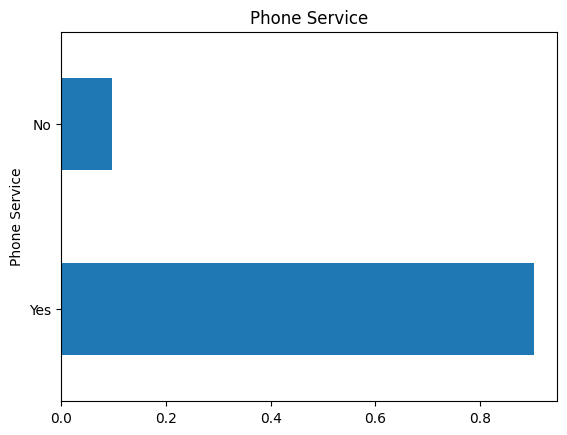

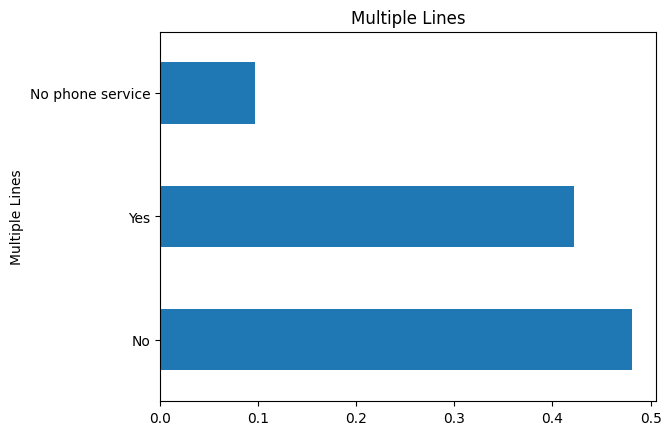

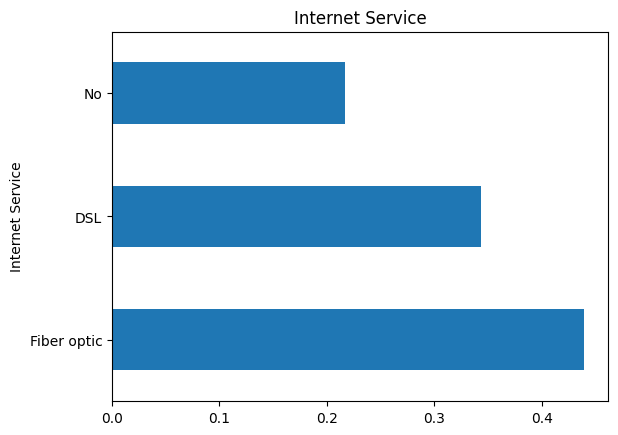

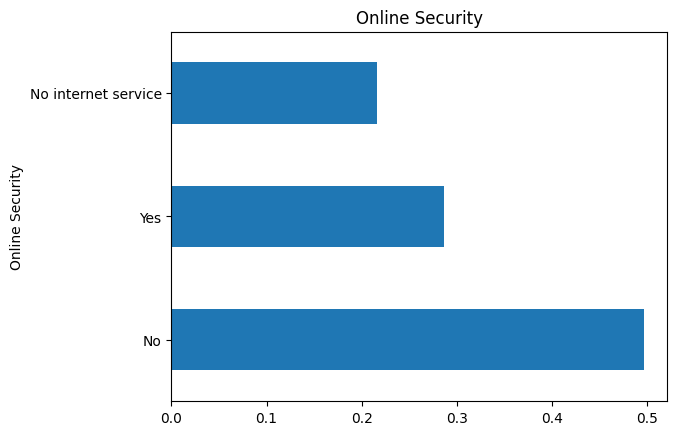

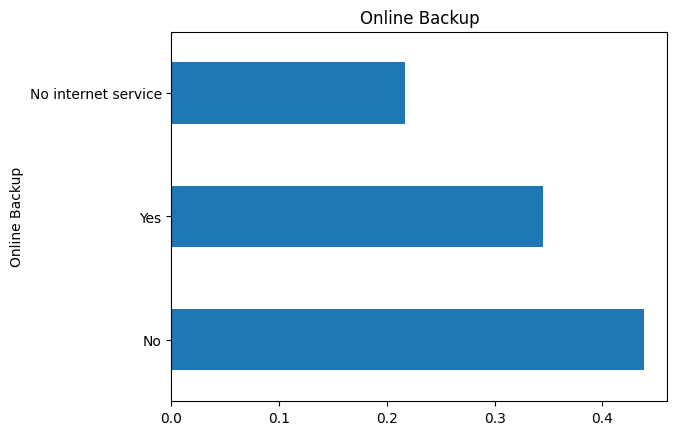

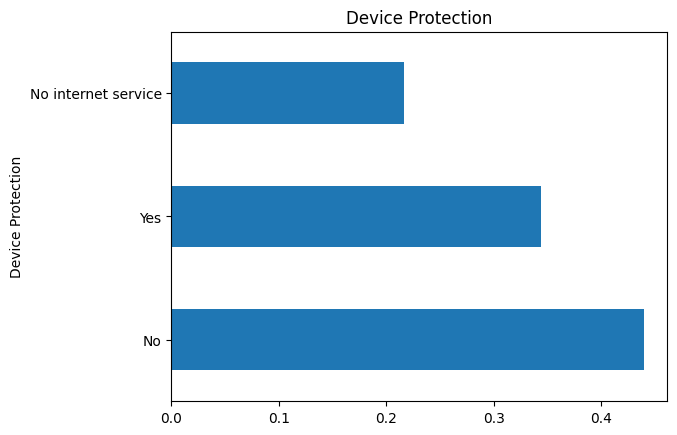

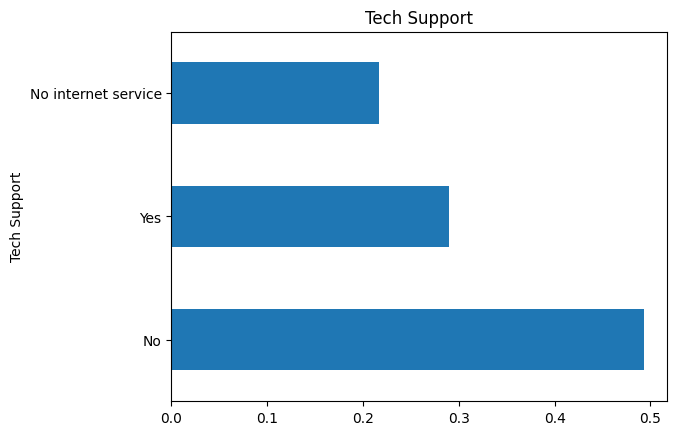

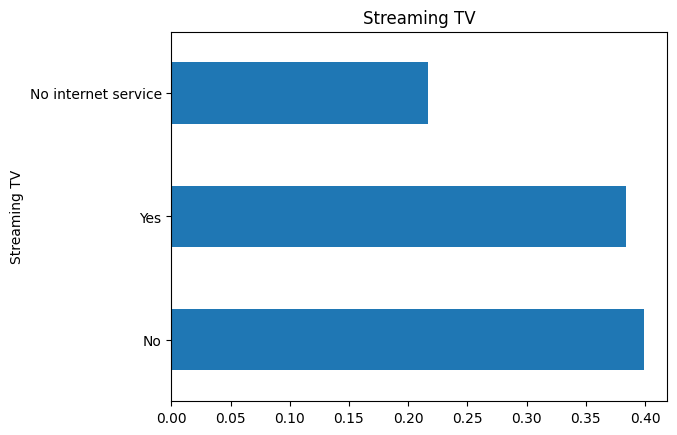

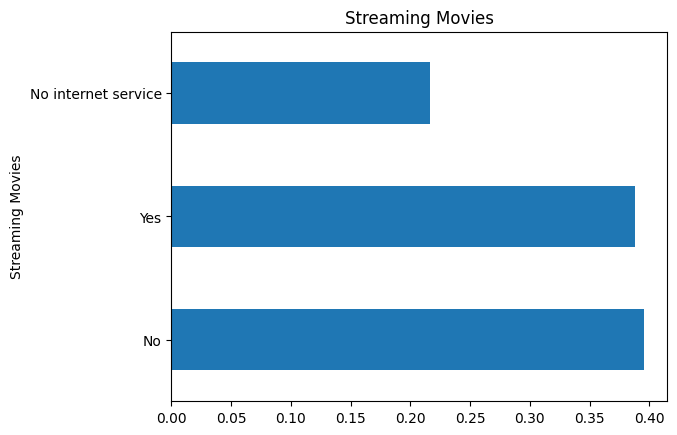

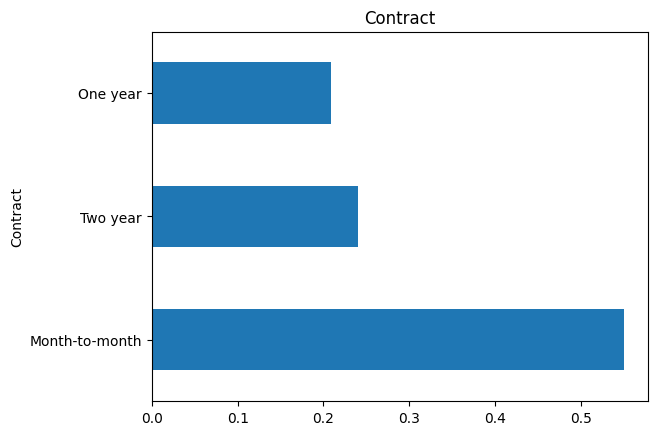

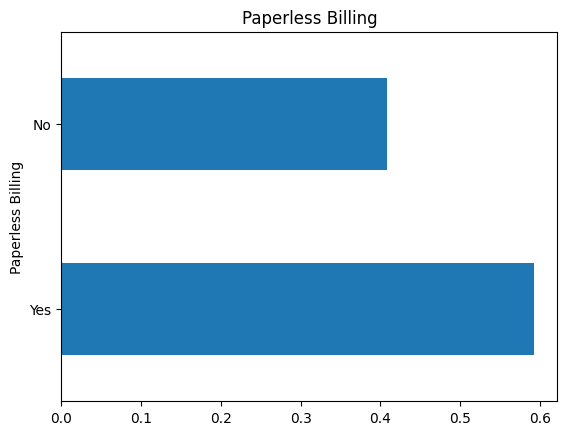

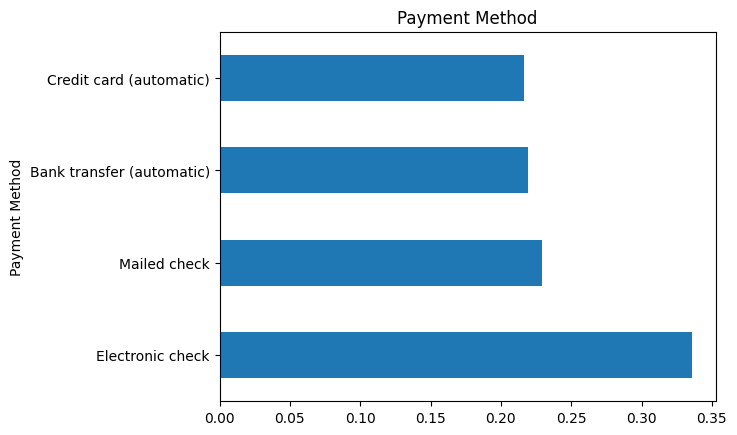

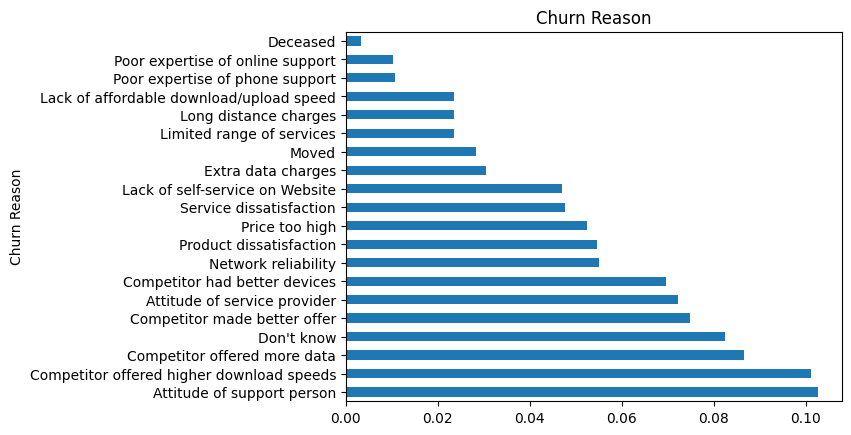

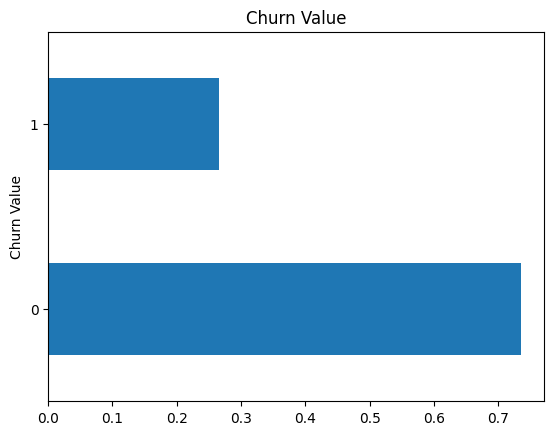

In [32]:
# Gráficos de barras con la frecuencia relativa de cada categoría
for var in cat_vars:
    plt.figure()
    df[var].value_counts(normalize=True).plot(kind='barh', title=var)
    plt.show();

In [33]:
# Frecuencias absolutas de cada categoría
for var in cat_vars:
    print(f'Categorías de la variable {var}:')
    print(df[var].value_counts())
    print('\n')

Categorías de la variable Gender:
Gender
Male      3555
Female    3488
Name: count, dtype: int64


Categorías de la variable Senior Citizen:
Senior Citizen
No     5901
Yes    1142
Name: count, dtype: int64


Categorías de la variable Partner:
Partner
No     3641
Yes    3402
Name: count, dtype: int64


Categorías de la variable Dependents:
Dependents
No     5416
Yes    1627
Name: count, dtype: int64


Categorías de la variable Phone Service:
Phone Service
Yes    6361
No      682
Name: count, dtype: int64


Categorías de la variable Multiple Lines:
Multiple Lines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


Categorías de la variable Internet Service:
Internet Service
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


Categorías de la variable Online Security:
Online Security
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64


Categoría

In [34]:
# Frecuencias relativas, para identificar categorías atípicas (menos del 1%)
for var in cat_vars:
    print(f'Frecuencia relativa (%) de la variable {var}:')
    print(round(df[var].value_counts(normalize=True)*100, 2))
    print('\n')

Frecuencia relativa (%) de la variable Gender:
Gender
Male      50.48
Female    49.52
Name: proportion, dtype: float64


Frecuencia relativa (%) de la variable Senior Citizen:
Senior Citizen
No     83.79
Yes    16.21
Name: proportion, dtype: float64


Frecuencia relativa (%) de la variable Partner:
Partner
No     51.7
Yes    48.3
Name: proportion, dtype: float64


Frecuencia relativa (%) de la variable Dependents:
Dependents
No     76.9
Yes    23.1
Name: proportion, dtype: float64


Frecuencia relativa (%) de la variable Phone Service:
Phone Service
Yes    90.32
No      9.68
Name: proportion, dtype: float64


Frecuencia relativa (%) de la variable Multiple Lines:
Multiple Lines
No                  48.13
Yes                 42.18
No phone service     9.68
Name: proportion, dtype: float64


Frecuencia relativa (%) de la variable Internet Service:
Internet Service
Fiber optic    43.96
DSL            34.37
No             21.67
Name: proportion, dtype: float64


Frecuencia relativa (%) de l

In [35]:
# Cardinalidad de las variables cualitativas
df.select_dtypes(include=['object']).describe().T

,count,unique,top,freq
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361
Multiple Lines,7043,3,No,3390
Internet Service,7043,3,Fiber optic,3096
Online Security,7043,3,No,3498
Online Backup,7043,3,No,3088
Device Protection,7043,3,No,3095


<div style="background:#fafafa; border:1px solid #d8d8d8; border-left:4px solid #555;border-radius:4px; padding:14px 18px; margin:6px 0; font-size:14.5px; color:#222; line-height:1.55;">
<div style="font-weight:700; font-size:13.5px; color:#555; text-transform:uppercase; letter-spacing:.4px; margin-bottom:10px;">Respuestas — Paso 5</div>
<p style="margin:14px 0 3px 0;"><b>¿Cómo se comportan las categóricas?</b></p>
<p>Hay de todo: variables balanceadas (<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Gender</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Partner</code>), moderadamente desbalanceadas (<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Dependents</code>, los servicios adicionales), muy desbalanceadas (<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Phone Service</code> 90/10, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Senior Citizen</code> 84/16) y variables de negocio con varias categorías repartidas (<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Contract</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Payment Method</code>). La variable objetivo está en 73/27.</p>
<p style="margin:14px 0 3px 0;"><b>¿Alta cardinalidad?</b></p>
<p>Ya no, se eliminaron en el paso anterior. Solo <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code> sigue con 20 categorías, y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Zip Code</code> con 1652.</p>
<p style="margin:14px 0 3px 0;"><b>¿Categorías atípicas?</b></p>
<p>Sí, en <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code>: <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Deceased</code> tiene solo 6 casos (menos del 1%). Las categorías <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">'No internet/phone service'</code> que aparecen bajas en otras variables no son atípicas, son redundantes con <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Internet Service</code>/<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Phone Service</code>.</p>
</div>

## Paso 6: Análisis bivariado

Se va a suponer que con este archivo de datos se desea hacer un modelo de aprendizaje de máquina que prediga la **Churn Value**.

Mediante análisis de gráficas responda las siguientes preguntas:

- ¿Cómo se relaciona cada una de las variables cuantitativas con la variable que se desea predecir?
- ¿Cómo se relaciona cada una de las variables cualitativas con la variable que se desea predecir?
- De acuerdo con estos análisis, ¿cuáles variables parecerían ser buenas predictoras, y cuáles no?

Antes de empezar hay que tener en cuenta que **tres variables no se pueden usar para predecir**
`Churn Value`, porque dependen directamente de ella y producirían fuga de datos:

- `Churn Label`: es la misma variable objetivo escrita como texto (Yes/No en lugar de 1/0).
- `Churn Reason`: la razón de cancelación solo se conoce **después** de que el cliente se fue.
- `Churn Score`: es el puntaje de riesgo que ya calculó IBM para predecir este mismo churn.

Se incluyen en el análisis para mostrar el problema, pero se descartan al final.

### Variables cuantitativas frente a Churn Value

In [36]:
# Promedio de cada variable cuantitativa según el cliente se haya ido o no
df.groupby('Churn Value')[cuanti].mean()

,Tenure Months,Monthly Charges,Total Charges,Churn Score,CLTV
Churn Value,,,,,
0,37.569965,61.265124,2549.911442,50.098183,4490.921337
1,17.979133,74.441332,1531.796094,82.510433,4149.414660


In [37]:
# Descripción completa por grupo de la variable más importante
df.groupby('Churn Value')['Tenure Months'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn Value,,,,,,,,
0,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
1,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


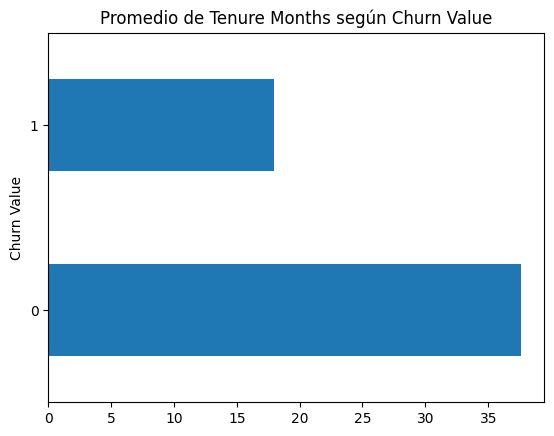

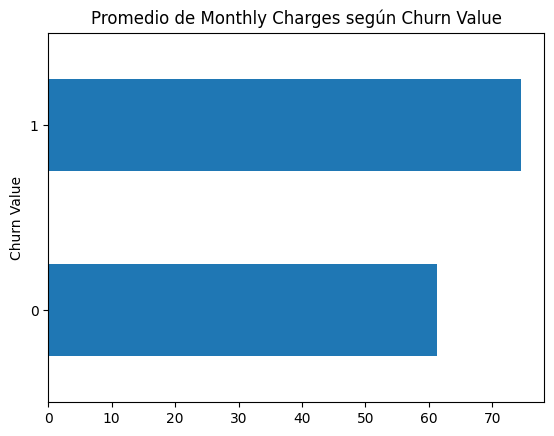

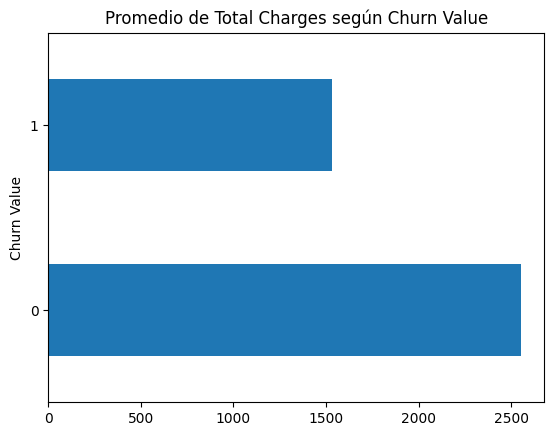

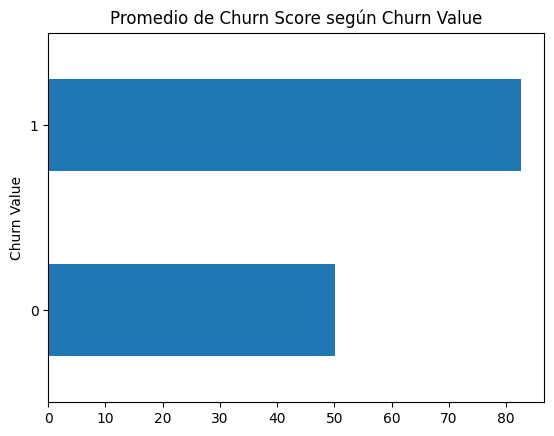

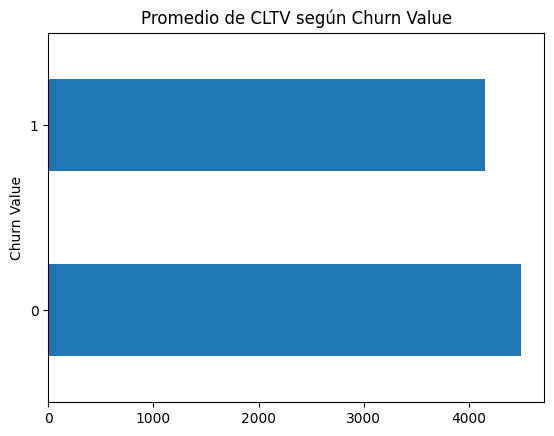

In [38]:
# Gráficos de barras con el promedio de cada variable cuantitativa por grupo
for col in cuanti:
    plt.figure()
    df.groupby('Churn Value')[col].mean().plot(
        kind='barh',
        title='Promedio de ' + col + ' según Churn Value'
        )
    plt.show();

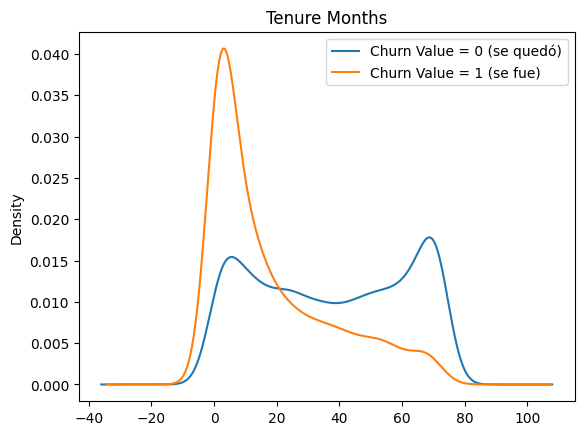

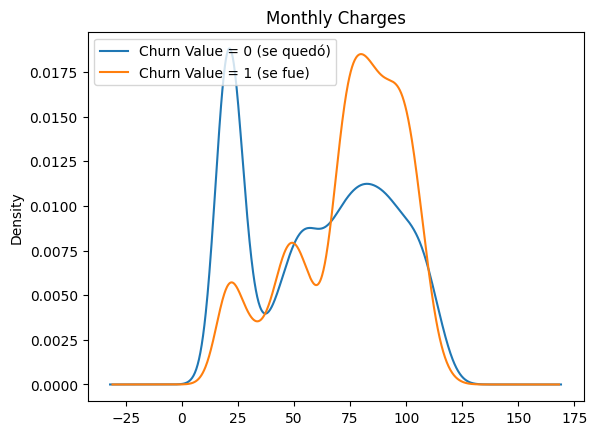

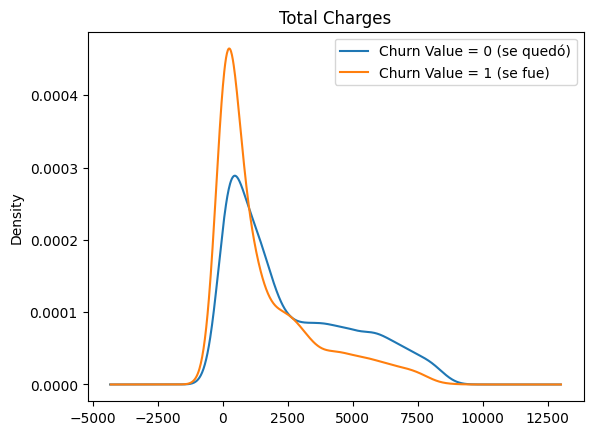

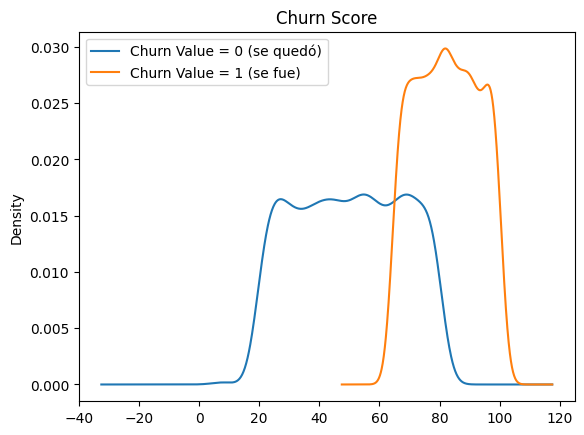

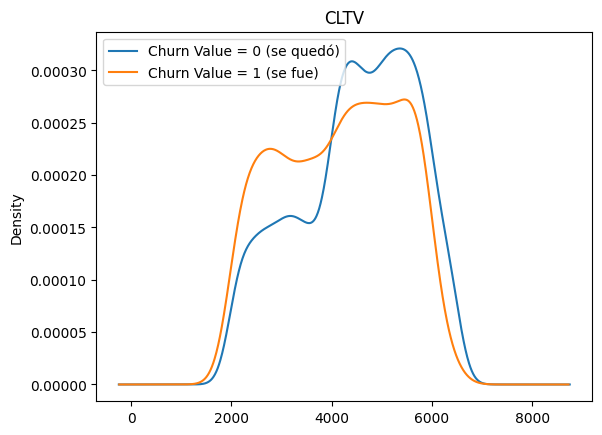

In [39]:
# Gráficos de densidad comparando los dos grupos
for col in cuanti:
    plt.figure()
    df[df['Churn Value'] == 0][col].plot(kind='kde', label='Churn Value = 0 (se quedó)')
    df[df['Churn Value'] == 1][col].plot(kind='kde', label='Churn Value = 1 (se fue)')
    plt.title(col)
    plt.legend()
    plt.show();

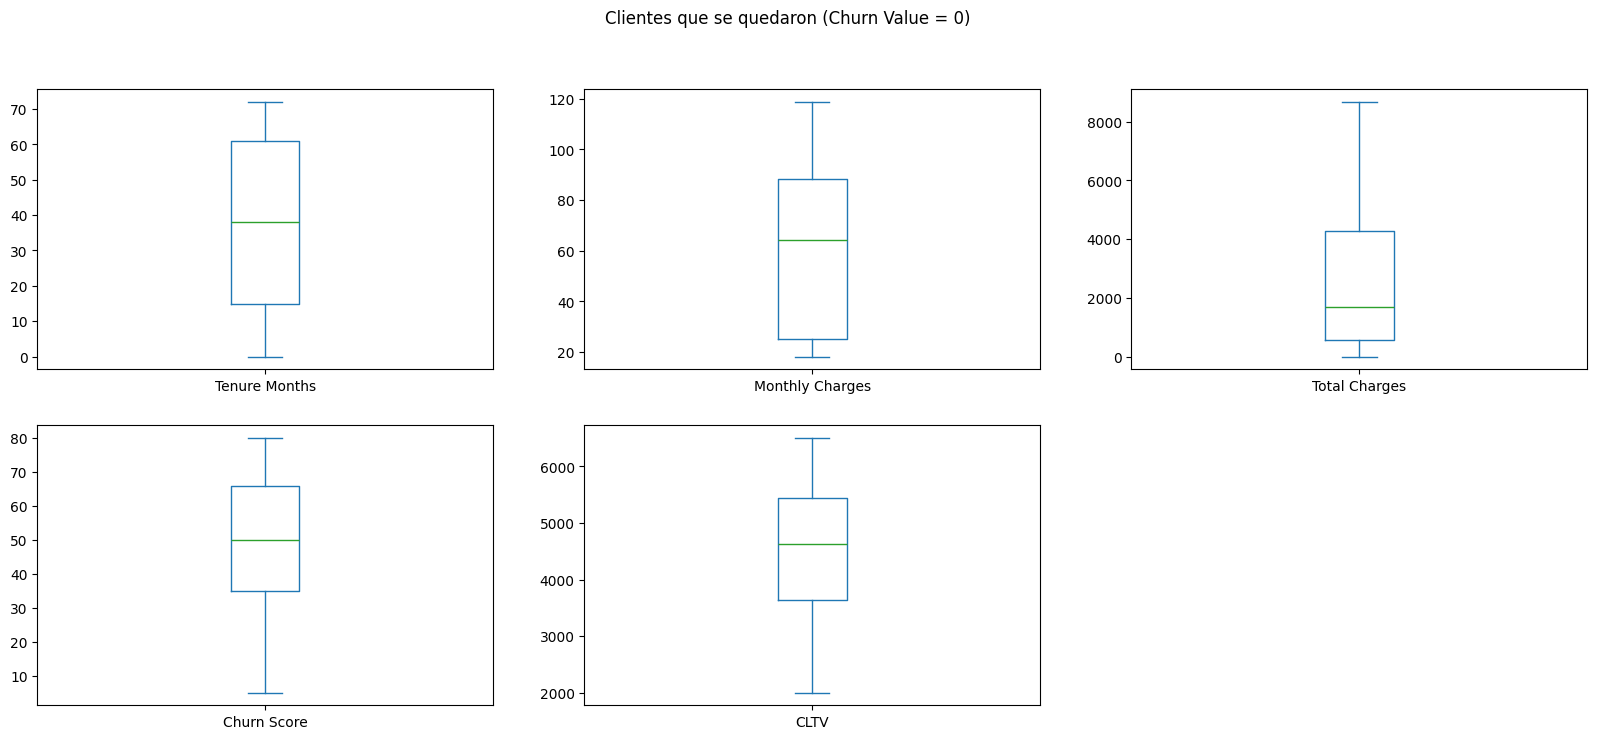

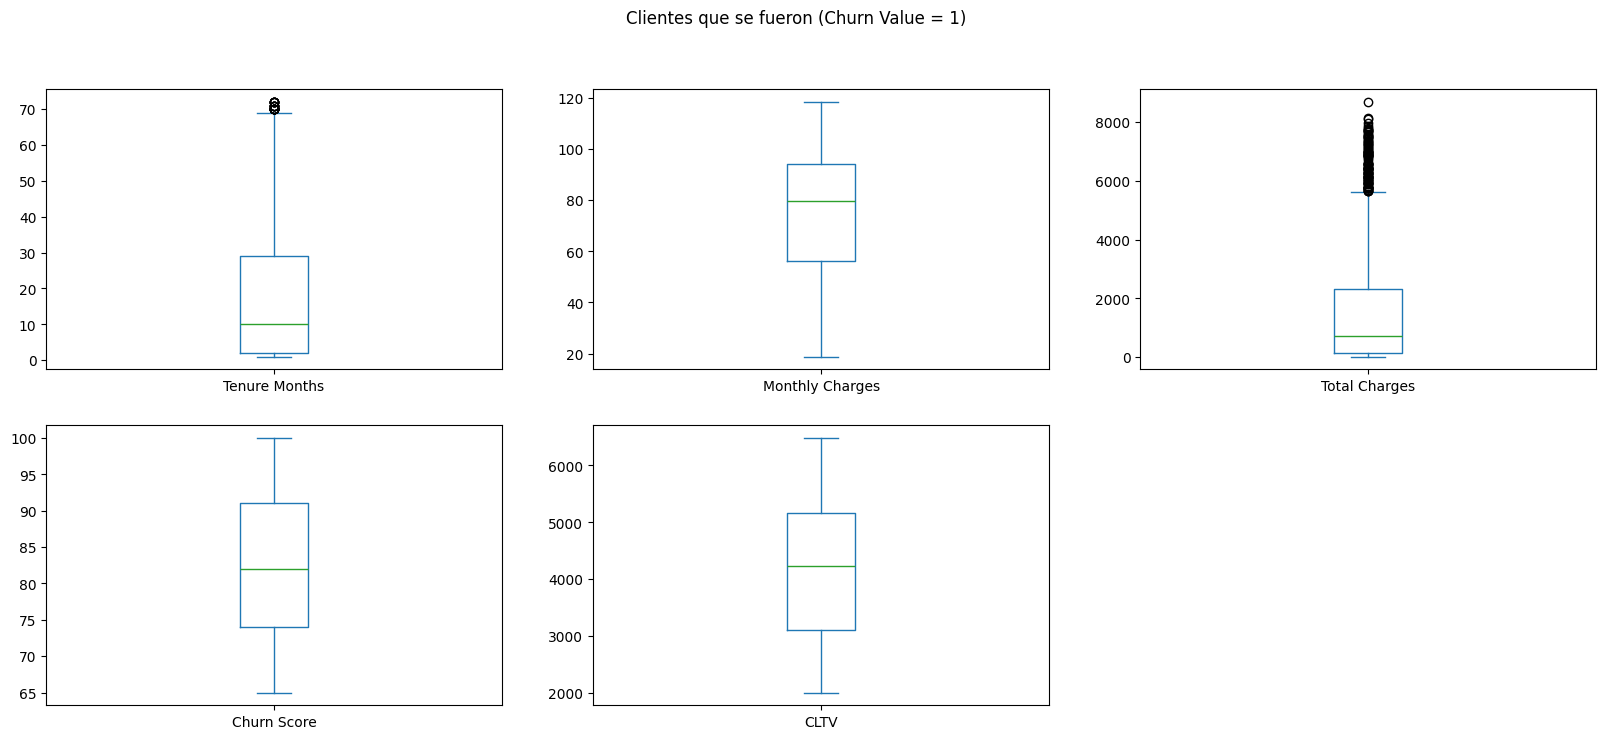

In [40]:
# Diagramas de caja de los clientes que se quedaron
df[df['Churn Value'] == 0][cuanti].plot(
    kind='box',
    figsize=(20, 8),
    subplots=True,
    layout=(2, 3),
    sharex=False,
    sharey=False,
    title='Clientes que se quedaron (Churn Value = 0)'
    )
plt.show()

# Diagramas de caja de los clientes que se fueron
df[df['Churn Value'] == 1][cuanti].plot(
    kind='box',
    figsize=(20, 8),
    subplots=True,
    layout=(2, 3),
    sharex=False,
    sharey=False,
    title='Clientes que se fueron (Churn Value = 1)'
    )
plt.show()

In [41]:
# También se revisan las variables geográficas, para ver si aportan algo
df.groupby('Churn Value')[['Zip Code', 'Latitude', 'Longitude']].mean()

,Zip Code,Latitude,Longitude
Churn Value,,,
0,93518.212215,36.287436,-119.804838
1,93532.352595,36.268614,-119.782388


### Variables cualitativas frente a Churn Value

Como `Churn Value` toma los valores 0 y 1, **su promedio dentro de cada categoría es directamente la
proporción de clientes que se fueron**. Multiplicando por 100 se obtiene el porcentaje de churn de
cada categoría.

In [42]:
# Variables cualitativas a analizar (sin la variable objetivo ni las de fuga de datos)
cat_pred = [var for var in cat_vars if var not in ['Churn Value', 'Churn Label', 'Churn Reason']]

print('Porcentaje de churn global: ', round(df['Churn Value'].mean()*100, 2), '%')
print('\nVariables cualitativas a analizar: ', len(cat_pred))

Porcentaje de churn global:  26.54 %

Variables cualitativas a analizar:  16


In [43]:
# Porcentaje de churn de cada categoría
for var in cat_pred:
    print(f'Porcentaje de churn según {var}:')
    print(round(df.groupby(var)['Churn Value'].mean()*100, 2))
    print('\n')

Porcentaje de churn según Gender:
Gender
Female    26.92
Male      26.16
Name: Churn Value, dtype: float64


Porcentaje de churn según Senior Citizen:
Senior Citizen
No     23.61
Yes    41.68
Name: Churn Value, dtype: float64


Porcentaje de churn según Partner:
Partner
No     32.96
Yes    19.66
Name: Churn Value, dtype: float64


Porcentaje de churn según Dependents:
Dependents
No     32.55
Yes     6.52
Name: Churn Value, dtype: float64


Porcentaje de churn según Phone Service:
Phone Service
No     24.93
Yes    26.71
Name: Churn Value, dtype: float64


Porcentaje de churn según Multiple Lines:
Multiple Lines
No                  25.04
No phone service    24.93
Yes                 28.61
Name: Churn Value, dtype: float64


Porcentaje de churn según Internet Service:
Internet Service
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn Value, dtype: float64


Porcentaje de churn según Online Security:
Online Security
No                     41.77
No internet service 

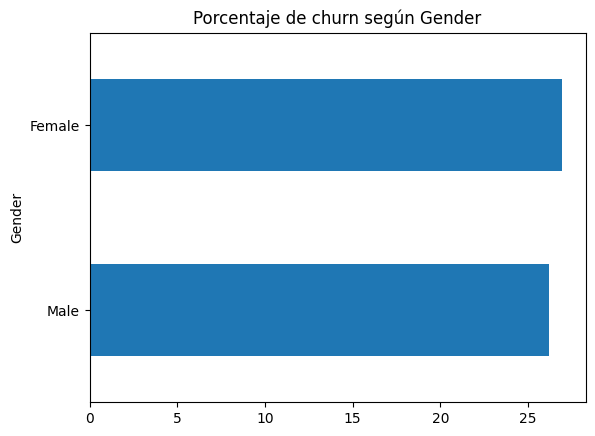

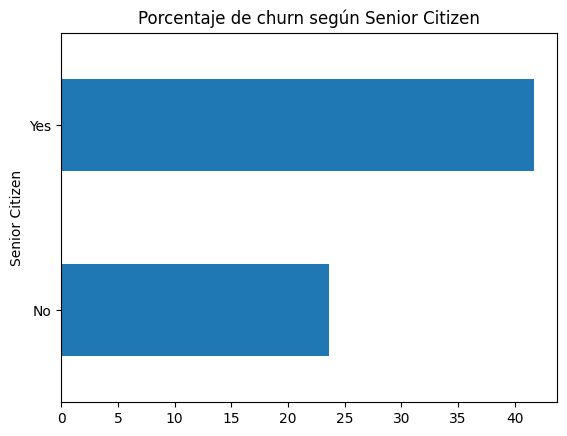

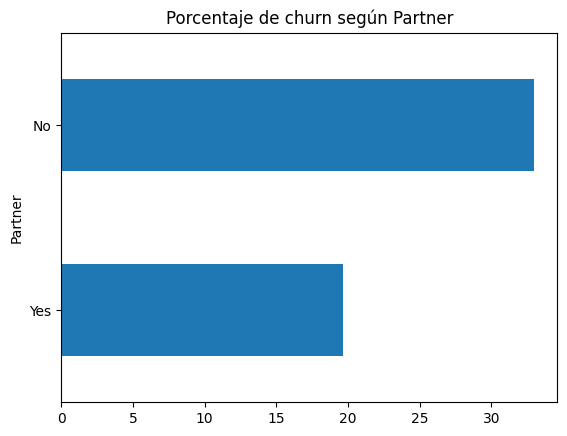

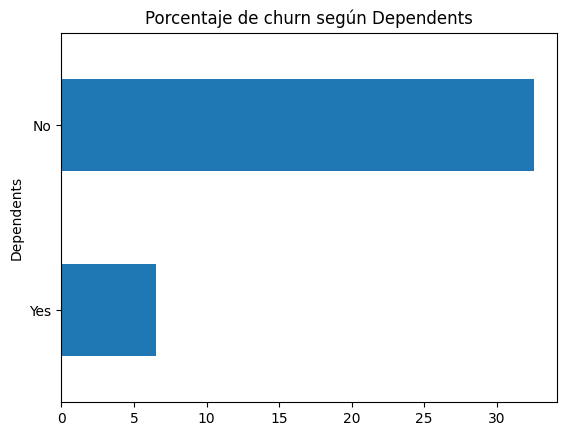

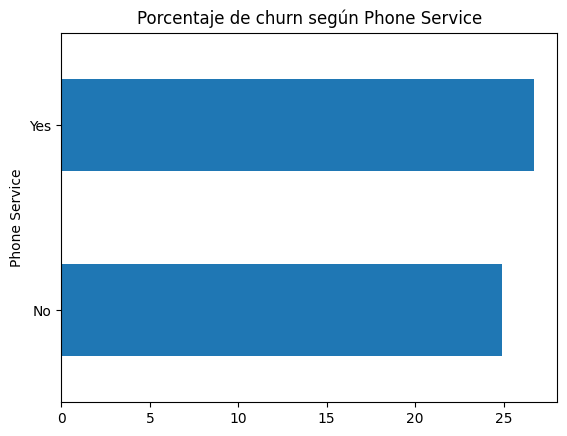

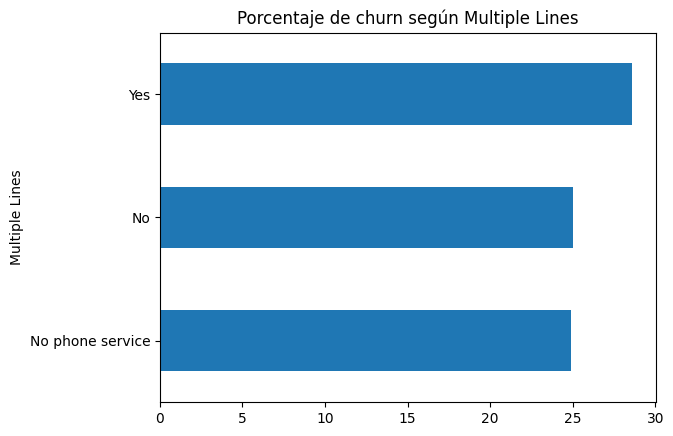

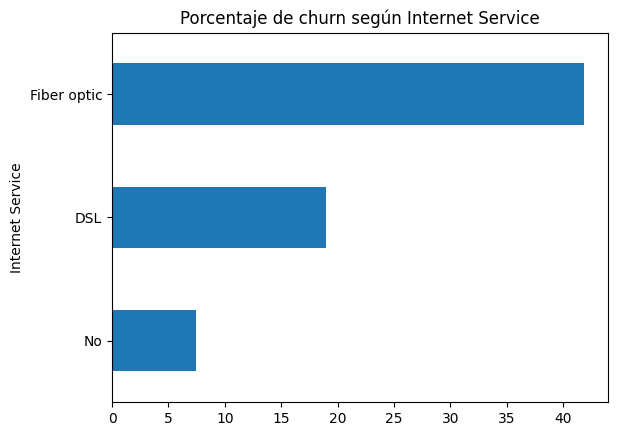

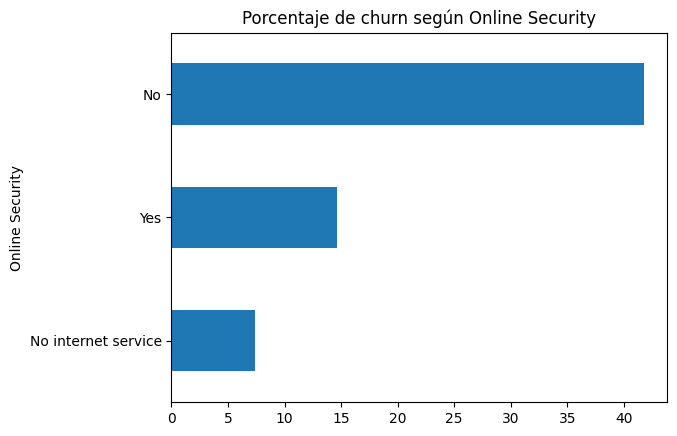

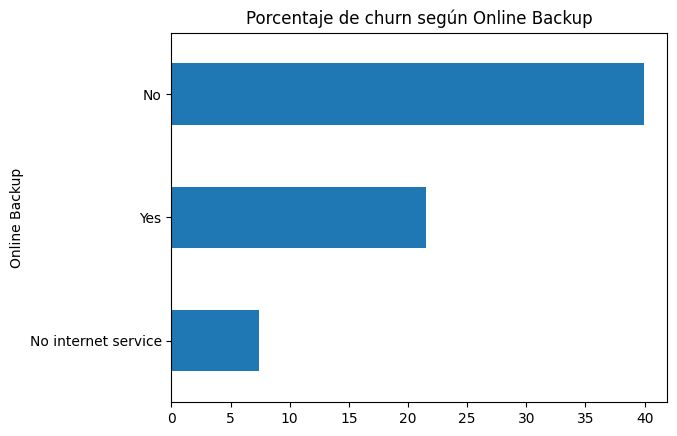

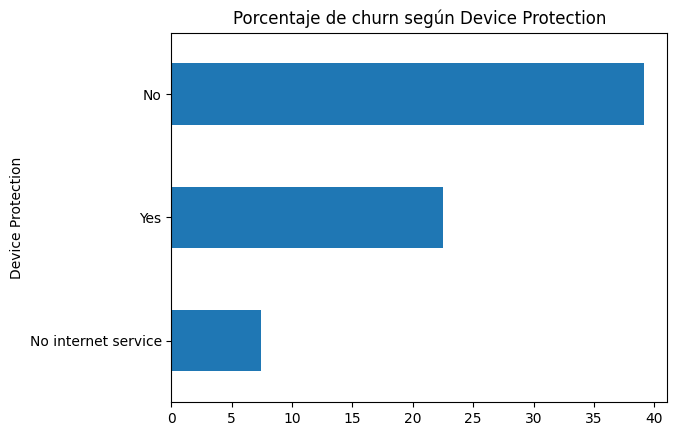

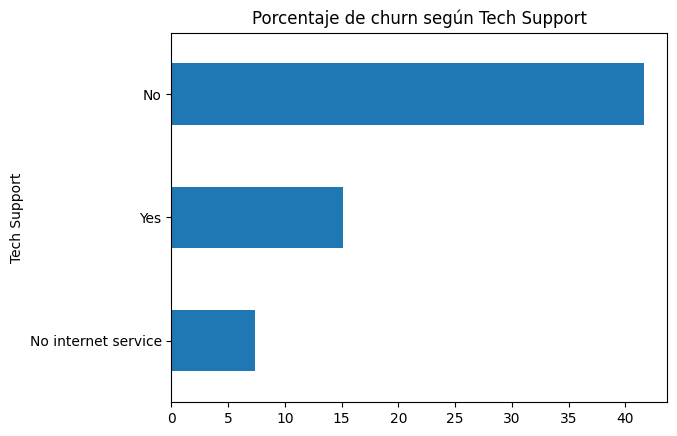

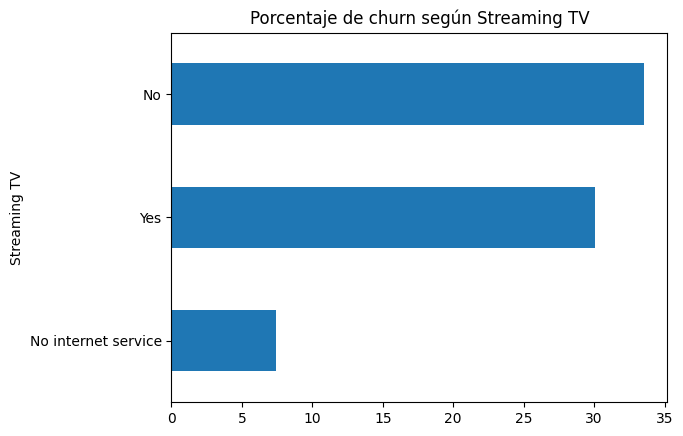

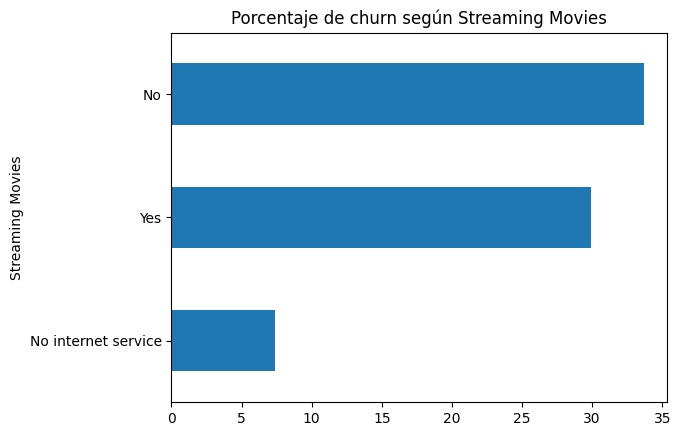

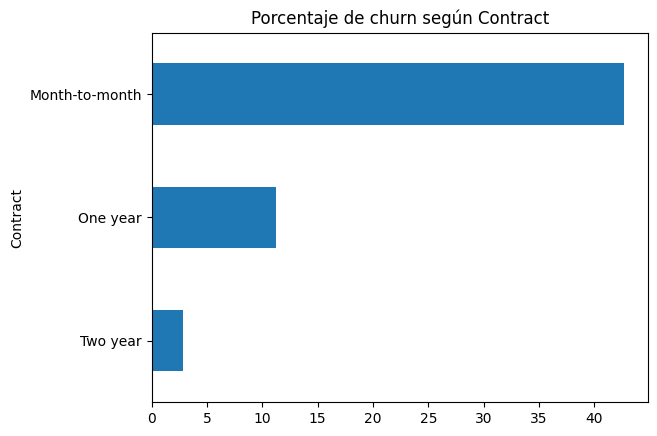

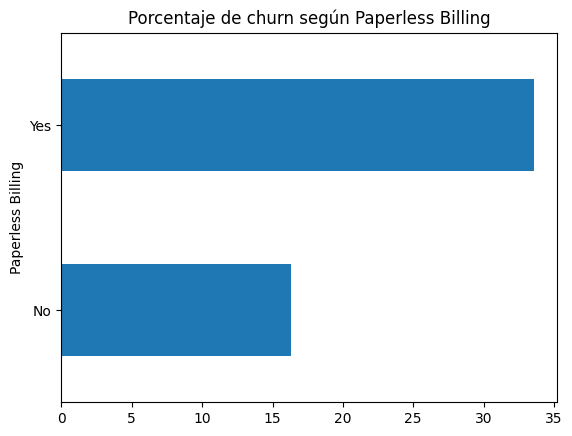

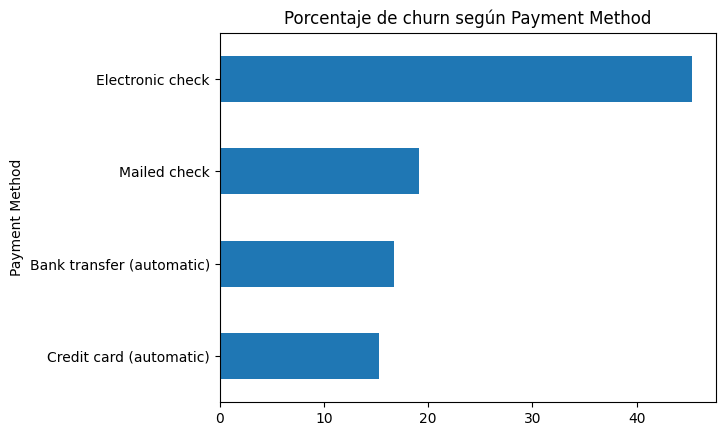

In [44]:
# Gráficos de barras con el porcentaje de churn de cada categoría
for var in cat_pred:
    plt.figure()
    (df.groupby(var)['Churn Value'].mean()*100).sort_values().plot(
        kind='barh',
        title='Porcentaje de churn según ' + var
        )
    plt.show();

In [45]:
# Se resume qué tanto separa cada variable: diferencia entre la categoría con más
# churn y la categoría con menos churn
resumen = []

for var in cat_pred:
    tasas = df.groupby(var)['Churn Value'].mean()*100
    resumen.append([var, round(tasas.min(), 2), round(tasas.max(), 2), round(tasas.max() - tasas.min(), 2)])

resumen = pd.DataFrame(resumen, columns=['variable', 'churn minimo %', 'churn maximo %', 'diferencia'])
resumen = resumen.sort_values('diferencia', ascending=False)
resumen

,variable,churn minimo %,churn maximo %,diferencia
13,Contract,2.83,42.71,39.88
6,Internet Service,7.40,41.89,34.49
7,Online Security,7.40,41.77,34.36
10,Tech Support,7.40,41.64,34.23
8,Online Backup,7.40,39.93,32.52
9,Device Protection,7.40,39.13,31.72
15,Payment Method,15.24,45.29,30.04
12,Streaming Movies,7.40,33.68,26.28
11,Streaming TV,7.40,33.52,26.12
3,Dependents,6.52,32.55,26.04


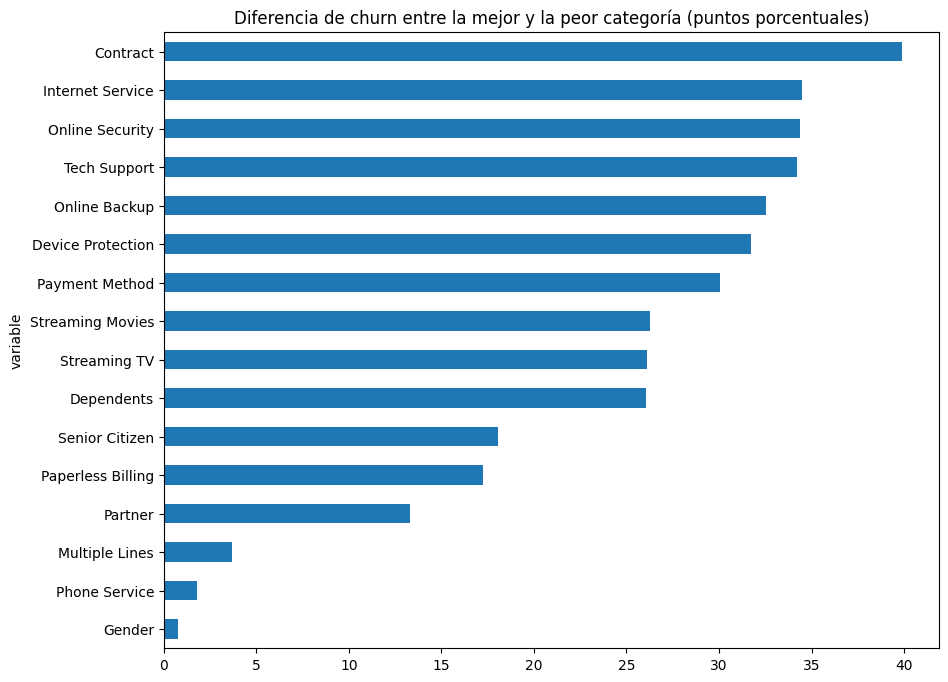

In [46]:
# Gráfico del resumen anterior
plt.figure()
resumen.set_index('variable')['diferencia'].sort_values().plot(
    kind='barh',
    figsize=(10, 8),
    title='Diferencia de churn entre la mejor y la peor categoría (puntos porcentuales)'
    )
plt.show();

Promedio de Churn Score según Churn Value:
Churn Value
0    50.098183
1    82.510433
Name: Churn Score, dtype: float64




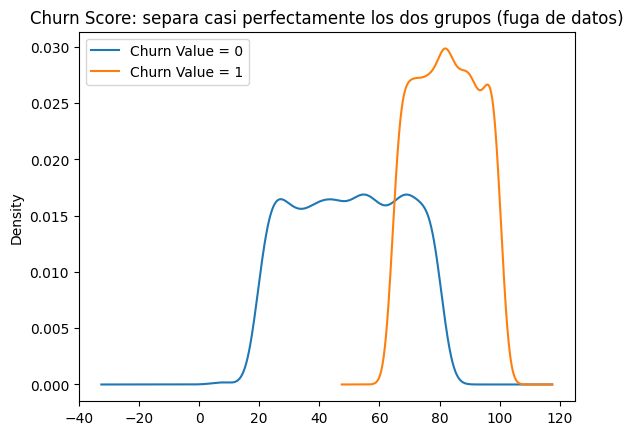

In [47]:
# Se comprueba la fuga de datos de Churn Score y Churn Label
print('Promedio de Churn Score según Churn Value:')
print(df.groupby('Churn Value')['Churn Score'].mean())
print('\n')

plt.figure()
df[df['Churn Value'] == 0]['Churn Score'].plot(kind='kde', label='Churn Value = 0')
df[df['Churn Value'] == 1]['Churn Score'].plot(kind='kde', label='Churn Value = 1')
plt.title('Churn Score: separa casi perfectamente los dos grupos (fuga de datos)')
plt.legend()
plt.show();

In [48]:
# Dataframe final que se usaría para entrenar el modelo
buenas = ['Contract', 'Tenure Months', 'Online Security', 'Tech Support', 'Internet Service',
          'Payment Method', 'Online Backup', 'Device Protection', 'Dependents',
          'Streaming Movies', 'Streaming TV', 'Monthly Charges', 'Total Charges',
          'Paperless Billing', 'Senior Citizen', 'Partner']

df_modelo = df[buenas + ['Churn Value']]
df_modelo.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 3668-QPYBK to 3186-AJIEK
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Contract           7043 non-null   object 
 1   Tenure Months      7043 non-null   int64  
 2   Online Security    7043 non-null   object 
 3   Tech Support       7043 non-null   object 
 4   Internet Service   7043 non-null   object 
 5   Payment Method     7043 non-null   object 
 6   Online Backup      7043 non-null   object 
 7   Device Protection  7043 non-null   object 
 8   Dependents         7043 non-null   object 
 9   Streaming Movies   7043 non-null   object 
 10  Streaming TV       7043 non-null   object 
 11  Monthly Charges    7043 non-null   float64
 12  Total Charges      7043 non-null   float64
 13  Paperless Billing  7043 non-null   object 
 14  Senior Citizen     7043 non-null   object 
 15  Partner            7043 non-null   object 
 16  Churn Value   

<div style="background:#fafafa; border:1px solid #d8d8d8; border-left:4px solid #555;border-radius:4px; padding:14px 18px; margin:6px 0; font-size:14.5px; color:#222; line-height:1.55;">
<div style="font-weight:700; font-size:13.5px; color:#555; text-transform:uppercase; letter-spacing:.4px; margin-bottom:10px;">Respuestas — Paso 6</div>
<p style="margin:14px 0 3px 0;"><b>Cuantitativas vs. Churn Value</b></p>
<p><code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tenure Months</code> es la que más se relaciona (18 meses de promedio si se va, 38 si se queda). <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Monthly Charges</code> también: quien se va paga 13 dólares más al mes. <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Total Charges</code> baja si se va, pero es un efecto derivado de la antigüedad. <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">CLTV</code> y las variables geográficas casi no aportan nada.</p>
<p style="margin:14px 0 3px 0;"><b>Cualitativas vs. Churn Value</b></p>
<p><code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Contract</code> es la más fuerte: 2.8% de churn en contratos de 2 años contra 42.7% en mes a mes. También pesan mucho <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Internet Service</code> (fibra óptica: 42% de churn), <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Online Security</code>/<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tech Support</code> (sin ellos, ~42%) y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Payment Method</code> (cheque electrónico: 45%). <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Gender</code> y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Phone Service</code> casi no cambian nada entre categorías.</p>
<p style="margin:14px 0 3px 0;"><b>¿Buenas y malas predictoras?</b></p>
<p>Buenas: <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Contract</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tenure Months</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Internet Service</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Online Security</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Tech Support</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Payment Method</code> y, con menos peso, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Online Backup</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Device Protection</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Streaming TV/Movies</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Dependents</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Senior Citizen</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Paperless Billing</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Partner</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Monthly/Total Charges</code>. Malas: <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Gender</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Phone Service</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Multiple Lines</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">CLTV</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Zip Code</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Latitude</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Longitude</code>. Y hay que descartar <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Label</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code> y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Score</code> por fuga de datos: solo existen o se calculan después del churn.</p>
</div>

<div style="background:#fafafa; border:1px solid #d8d8d8; border-left:4px solid #555;border-radius:4px; padding:14px 18px; margin:6px 0; font-size:14.5px; color:#222; line-height:1.55;">
<div style="font-weight:700; font-size:13.5px; color:#555; text-transform:uppercase; letter-spacing:.4px; margin-bottom:10px;">Conclusiones</div>
<p>Dataset limpio: 7043 filas sin duplicados, con <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">CustomerID</code> como clave. Los únicos nulos son estructurales
(<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Total Charges</code> por clientes nuevos, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code> por clientes que no se fueron). Ninguna variable cuantitativa
es normal ni tiene outliers. El cliente típico en riesgo de churn: pocos meses de antigüedad, contrato mes a mes,
fibra óptica, sin seguridad ni soporte técnico, paga con cheque electrónico. Para el modelo hay que descartar
<code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Label</code>, <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Reason</code> y <code style="background:#eee; padding:1px 4px; border-radius:3px; font-family:monospace; font-size:13px;">Churn Score</code> por fuga de datos.</p>
</div>